# Gaze-Object Probabilistic Heatmap Video Demonstration

Render the probabilistic gaze heatmap and object posterior result back onto a world-camera video. Gaze and objects are shown as distributions: gaze uncertainty is drawn as a heatmap around gaze samples, and object boxes are colored by posterior probability.


## Setup

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

DATASET_ROOT = Path("/home/julius/datasets/seminar_object_detection")
VIDEO_ROOT = DATASET_ROOT / "iAssistADL_dataset_export_2026-05-18" / "world_camera_videos"
LOWER_ROOT = DATASET_ROOT / "lower_feature_outcome"
UPPER_ROOT = DATASET_ROOT / "upper_feature_outcome"
OUTPUT_ROOT = DATASET_ROOT / "video_demostration"

GAZE_ROOT = LOWER_ROOT / "gaze_xy_filled_sensor_csv"
YOLO_ROOT = LOWER_ROOT / "yolo_object_outcome_csv"
PROB_ROOT = UPPER_ROOT / "gaze_object_features" / "probabilistic_heatmap_frame_aggregation"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

SELECTED_PARTICIPANT = "IA_4_H_14"
SELECTED_FULL_ID = "IA_4_H_14_Chaos_several_Tasks_combine1"

WINDOW_SECONDS = 30
DEMO_SECONDS = None  # None renders the full selected complex action. Use a number for a short demo.
MAX_GAZE_POINTS_PER_FRAME = 10
MAX_OBJECTS_TO_DRAW = 10
HEATMAP_SIGMA_PX = 50
HEATMAP_RADIUS_FACTOR = 2.5
HEATMAP_ALPHA = 0.42
SHOW_HEATMAP = True

video_path = VIDEO_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_world_camera.mp4"
gaze_path = GAZE_ROOT / SELECTED_PARTICIPANT / SELECTED_FULL_ID / "eye_tracker__gaze.csv"
yolo_path = YOLO_ROOT / f"{SELECTED_FULL_ID}_world_camera.csv"
prob_frame_path = PROB_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_gaze_yolo_probabilistic_heatmap_frame.csv"
prob_object_path = PROB_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_gaze_yolo_probabilistic_heatmap_frame_objects.csv"
duration_label = "full" if DEMO_SECONDS is None else f"{int(DEMO_SECONDS)}s"
output_video_path = OUTPUT_ROOT / f"{SELECTED_FULL_ID}_gaze_object_probabilistic_heatmap_{duration_label}_demo.mp4"

for path in [video_path, gaze_path, yolo_path, prob_frame_path, prob_object_path]:
    assert path.exists(), f"Missing file: {path}"

video_path, prob_frame_path, prob_object_path, output_video_path


(PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_world_camera.mp4'),
 PosixPath('/home/julius/datasets/seminar_object_detection/upper_feature_outcome/gaze_object_features/probabilistic_heatmap_frame_aggregation/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_yolo_probabilistic_heatmap_frame.csv'),
 PosixPath('/home/julius/datasets/seminar_object_detection/upper_feature_outcome/gaze_object_features/probabilistic_heatmap_frame_aggregation/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_yolo_probabilistic_heatmap_frame_objects.csv'),
 PosixPath('/home/julius/datasets/seminar_object_detection/video_demostration/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_object_probabilistic_heatmap_full_demo.mp4'))

## Pick A High-Posterior Window

The full recording can be long, so this chooses the 30-second window with the most frames containing positive object posterior probability.


In [2]:
prob_frame_df = pd.read_csv(prob_frame_path)
prob_frame_df["best_object_probability"] = pd.to_numeric(prob_frame_df["best_object_probability"], errors="coerce")
prob_frame_df["object_probability_normalized_entropy"] = pd.to_numeric(prob_frame_df["object_probability_normalized_entropy"], errors="coerce")

cap = cv2.VideoCapture(str(video_path))
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

if not fps or np.isnan(fps):
    fps = 30

window_frames = int(round(WINDOW_SECONDS * fps))
prob_frame_df = prob_frame_df.sort_values("video_frame_idx").copy()
prob_frame_df["has_probability"] = prob_frame_df["best_object_probability"] > 0

rolling_probs = (
    prob_frame_df.set_index("video_frame_idx")["has_probability"]
    .reindex(range(frame_count), fill_value=False)
    .astype(int)
    .rolling(window_frames, min_periods=1)
    .sum()
)

best_end_frame = int(rolling_probs.idxmax())
START_FRAME = max(0, best_end_frame - window_frames + 1)
END_FRAME = min(frame_count - 1, START_FRAME + window_frames - 1)

video_info = {
    "fps": fps,
    "frame_count": frame_count,
    "width": width,
    "height": height,
    "start_frame": START_FRAME,
    "end_frame": END_FRAME,
    "window_seconds": (END_FRAME - START_FRAME + 1) / fps,
    "posterior_frames_in_window": int(rolling_probs.max()),
}
video_info


{'fps': 30.0,
 'frame_count': 3882,
 'width': 1600,
 'height': 1200,
 'start_frame': 555,
 'end_frame': 1454,
 'window_seconds': 30.0,
 'posterior_frames_in_window': 900}

## Load Gaze, YOLO, And Posterior Data

In [3]:
gaze_df = pd.read_csv(gaze_path)
yolo_df = pd.read_csv(yolo_path)
prob_object_df = pd.read_csv(prob_object_path)

for col in ["video_frame_idx", "x", "y"]:
    gaze_df[col] = pd.to_numeric(gaze_df[col], errors="coerce")
for col in ["frame_id", "class_id", "confidence", "x1", "y1", "x2", "y2"]:
    yolo_df[col] = pd.to_numeric(yolo_df[col], errors="coerce")
for col in ["video_frame_idx", "detection_idx_in_frame", "class_id", "confidence", "x1", "y1", "x2", "y2", "object_posterior_probability", "object_sigma", "raw_overlap_score", "confidence_weighted_score"]:
    prob_object_df[col] = pd.to_numeric(prob_object_df[col], errors="coerce")

gaze_df = gaze_df[np.isfinite(gaze_df["video_frame_idx"])].copy()
gaze_df["video_frame_idx"] = gaze_df["video_frame_idx"].astype(int)
yolo_df = yolo_df[np.isfinite(yolo_df["frame_id"])].copy()
yolo_df["frame_id"] = yolo_df["frame_id"].astype(int)
prob_object_df = prob_object_df[np.isfinite(prob_object_df["video_frame_idx"])].copy()
prob_object_df["video_frame_idx"] = prob_object_df["video_frame_idx"].astype(int)

gaze_by_frame = {frame: df for frame, df in gaze_df.groupby("video_frame_idx")}
yolo_by_frame = {frame: df for frame, df in yolo_df.groupby("frame_id")}
prob_object_by_frame = {frame: df for frame, df in prob_object_df.groupby("video_frame_idx")}
prob_summary_by_frame = prob_frame_df.set_index("video_frame_idx").to_dict("index")

print("gaze rows:", len(gaze_df))
print("yolo rows:", len(yolo_df))
print("posterior object rows:", len(prob_object_df))


gaze rows: 19565
yolo rows: 31786
posterior object rows: 31786


## Rendering Helpers

In [4]:
def posterior_to_color(prob):
    prob = 0.0 if pd.isna(prob) else float(prob)
    prob = max(0.0, min(1.0, prob))
    # BGR: low=blue, mid=yellow, high=red
    red = int(255 * prob)
    green = int(255 * (1.0 - abs(prob - 0.5) * 2.0))
    blue = int(255 * (1.0 - prob))
    return (blue, green, red)


def draw_label(frame, text, xy, color, font_scale=0.55, thickness=1):
    x, y = int(xy[0]), int(xy[1])
    font = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), baseline = cv2.getTextSize(text, font, font_scale, thickness)
    cv2.rectangle(frame, (x, y - th - baseline - 4), (x + tw + 6, y), color, -1)
    cv2.putText(frame, text, (x + 3, y - baseline - 2), font, font_scale, (255, 255, 255), thickness, cv2.LINE_AA)


def add_gaze_heatmap(frame, frame_gaze):
    if not SHOW_HEATMAP:
        return frame
    if frame_gaze is None or frame_gaze.empty:
        return frame

    valid_gaze = frame_gaze[np.isfinite(frame_gaze["x"]) & np.isfinite(frame_gaze["y"])]
    if valid_gaze.empty:
        return frame

    heat = np.zeros(frame.shape[:2], dtype=np.float32)
    radius = int(round(HEATMAP_SIGMA_PX * HEATMAP_RADIUS_FACTOR))
    size = radius * 2 + 1
    axis = np.arange(size, dtype=np.float32) - radius
    xx, yy = np.meshgrid(axis, axis)
    kernel = np.exp(-(xx * xx + yy * yy) / (2 * HEATMAP_SIGMA_PX * HEATMAP_SIGMA_PX)).astype(np.float32)

    for _, gaze in valid_gaze.iterrows():
        gx, gy = int(round(gaze["x"])), int(round(gaze["y"]))
        x1, x2 = max(0, gx - radius), min(frame.shape[1], gx + radius + 1)
        y1, y2 = max(0, gy - radius), min(frame.shape[0], gy + radius + 1)
        if x1 >= x2 or y1 >= y2:
            continue
        kx1, kx2 = x1 - (gx - radius), size - ((gx + radius + 1) - x2)
        ky1, ky2 = y1 - (gy - radius), size - ((gy + radius + 1) - y2)
        heat[y1:y2, x1:x2] += kernel[ky1:ky2, kx1:kx2]

    if heat.max() <= 0:
        return frame

    heat_norm = np.uint8(np.clip(heat / heat.max() * 255, 0, 255))
    heat_color = cv2.applyColorMap(heat_norm, cv2.COLORMAP_TURBO)
    mask = heat_norm > 4
    blended = cv2.addWeighted(frame, 1.0 - HEATMAP_ALPHA, heat_color, HEATMAP_ALPHA, 0)
    frame[mask] = blended[mask]
    return frame


def draw_overlay(frame, frame_idx, frame_gaze, frame_yolo, frame_objects, frame_summary):
    frame = add_gaze_heatmap(frame, frame_gaze)

    if frame_yolo is not None and not frame_yolo.empty:
        for _, box in frame_yolo.iterrows():
            x1, y1, x2, y2 = [int(round(box[c])) for c in ["x1", "y1", "x2", "y2"]]
            cv2.rectangle(frame, (x1, y1), (x2, y2), (55, 55, 55), 1)

    if frame_objects is not None and not frame_objects.empty:
        top_objects = frame_objects.sort_values("object_posterior_probability", ascending=False).head(MAX_OBJECTS_TO_DRAW)
        for rank, (_, obj) in enumerate(top_objects.iterrows()):
            prob = float(obj["object_posterior_probability"])
            x1, y1, x2, y2 = [int(round(obj[c])) for c in ["x1", "y1", "x2", "y2"]]
            color = posterior_to_color(prob)
            thickness = 4 if rank == 0 else 2
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, thickness)
            label = f"class {int(obj['class_id'])} p={prob:.2f}"
            draw_label(frame, label, (x1, max(18, y1 - 4)), color)

    if frame_gaze is not None and not frame_gaze.empty:
        valid_gaze = frame_gaze[np.isfinite(frame_gaze["x"]) & np.isfinite(frame_gaze["y"])]
        for _, gaze in valid_gaze.tail(MAX_GAZE_POINTS_PER_FRAME).iterrows():
            gx, gy = int(round(gaze["x"])), int(round(gaze["y"]))
            cv2.circle(frame, (gx, gy), 6, (255, 255, 255), -1)
            cv2.circle(frame, (gx, gy), 10, (0, 0, 0), 2)

    best_class = frame_summary.get("best_class", "NA") if frame_summary else "NA"
    best_prob = frame_summary.get("best_object_probability", np.nan) if frame_summary else np.nan
    entropy = frame_summary.get("object_probability_normalized_entropy", np.nan) if frame_summary else np.nan
    status = f"{SELECTED_FULL_ID} | frame {frame_idx} | best {best_class} p={float(best_prob) if pd.notna(best_prob) else 0:.2f} entropy={float(entropy) if pd.notna(entropy) else 0:.2f}"
    draw_label(frame, status, (12, 30), (30, 30, 30), font_scale=0.6, thickness=1)
    return frame


## Preview One Frame

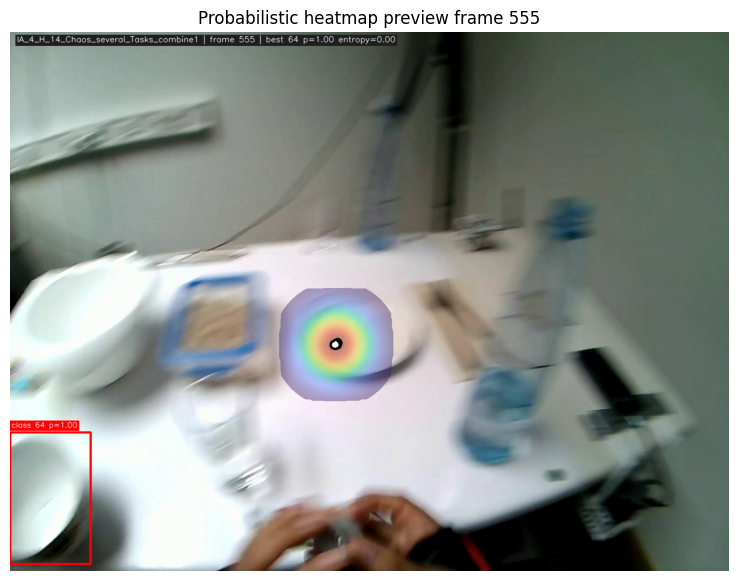

In [5]:
preview_frame_idx = START_FRAME
cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, preview_frame_idx)
ok, preview = cap.read()
cap.release()
assert ok, f"Could not read frame {preview_frame_idx}"

preview = draw_overlay(
    preview,
    preview_frame_idx,
    gaze_by_frame.get(preview_frame_idx),
    yolo_by_frame.get(preview_frame_idx),
    prob_object_by_frame.get(preview_frame_idx),
    prob_summary_by_frame.get(preview_frame_idx, {}),
)

preview_rgb = cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 7))
plt.imshow(preview_rgb)
plt.axis("off")
plt.title(f"Probabilistic heatmap preview frame {preview_frame_idx}")
plt.show()


## Render Demo Video

In [6]:
if DEMO_SECONDS is None:
    render_end_frame = END_FRAME
else:
    render_end_frame = min(END_FRAME, START_FRAME + int(round(DEMO_SECONDS * fps)) - 1)
render_frame_count = render_end_frame - START_FRAME + 1

print(f"Rendering {render_frame_count} frames from {START_FRAME} to {render_end_frame}", flush=True)
print(f"fps={fps:.3f}, size={width}x{height}, heatmap={SHOW_HEATMAP}, demo_seconds={DEMO_SECONDS}", flush=True)
print(f"Output: {output_video_path}", flush=True)

cap = cv2.VideoCapture(str(video_path))
assert cap.isOpened(), f"Could not open video: {video_path}"
cap.set(cv2.CAP_PROP_POS_FRAMES, START_FRAME)


def open_video_writer(path, fps, size):
    codecs = ["mp4v", "avc1", "XVID"]
    for codec in codecs:
        fourcc = cv2.VideoWriter_fourcc(*codec)
        writer = cv2.VideoWriter(str(path), fourcc, fps, size)
        if writer.isOpened():
            print(f"VideoWriter opened with codec={codec}", flush=True)
            return writer
        writer.release()
    raise RuntimeError(f"Could not open writer for: {path}")


writer = open_video_writer(output_video_path, fps, (width, height))
written = 0

for frame_idx in tqdm(range(START_FRAME, render_end_frame + 1), desc="Rendering probabilistic heatmap demo", unit="frame", mininterval=0.5):
    ok, frame = cap.read()
    if not ok:
        print(f"Stopped early at frame {frame_idx}", flush=True)
        break

    frame = draw_overlay(
        frame,
        frame_idx,
        gaze_by_frame.get(frame_idx),
        yolo_by_frame.get(frame_idx),
        prob_object_by_frame.get(frame_idx),
        prob_summary_by_frame.get(frame_idx, {}),
    )
    writer.write(frame)
    written += 1

writer.release()
cap.release()

if written == 0:
    raise RuntimeError("No frames were written. Check START_FRAME/video path.")

size_mb = output_video_path.stat().st_size / (1024 * 1024) if output_video_path.exists() else 0
print(f"Saved: {output_video_path}", flush=True)
print(f"Written frames: {written}, file size: {size_mb:.2f} MB", flush=True)


Rendering 900 frames from 555 to 1454
fps=30.000, size=1600x1200, heatmap=True, demo_seconds=None
Output: /home/julius/datasets/seminar_object_detection/video_demostration/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_object_probabilistic_heatmap_full_demo.mp4
VideoWriter opened with codec=mp4v


Rendering probabilistic heatmap demo:   0%|          | 0/900 [00:00<?, ?frame/s]

Saved: /home/julius/datasets/seminar_object_detection/video_demostration/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_object_probabilistic_heatmap_full_demo.mp4
Written frames: 900, file size: 86.64 MB


## Optional: Inspect Posterior Objects For The Selected Window

In [7]:
posterior_objects_in_window_df = prob_object_df[
    (prob_object_df["video_frame_idx"] >= START_FRAME)
    & (prob_object_df["video_frame_idx"] <= END_FRAME)
].sort_values(["video_frame_idx", "object_posterior_probability"], ascending=[True, False])

posterior_objects_in_window_df.head(20)


,video_frame_idx,detection_idx_in_frame,class_id,confidence,x1,y1,x2,y2,object_center_x,object_center_y,gaze_sigma,object_sigma,class_sigma_factor,class_score_factor,valid_gaze_sample_count,raw_overlap_score,confidence_weighted_score,object_posterior_probability
4120,555,0,64,0.531654,0.173893,890.585999,179.089264,1184.193237,89.631578,1037.389618,50.0,171.912711,1.00,1.00,4,1.456626e-09,7.744214e-10,1.000000
4121,556,0,41,0.365112,306.228210,789.630615,552.098206,1089.969971,429.163208,939.800293,50.0,194.072012,1.00,1.00,4,6.581094e-07,2.402839e-07,1.000000
4126,557,4,39,0.415461,918.568848,392.699280,1133.058960,885.218201,1025.813904,638.958740,50.0,268.598630,1.00,1.00,4,1.164160e-06,4.836636e-07,0.583035
4124,557,2,60,0.474689,8.053589,411.597595,1481.436157,1200.000000,744.744873,805.798798,50.0,292.435135,0.35,0.25,4,1.683097e-06,1.997371e-07,0.240774
4125,557,3,41,0.471493,256.163116,819.773071,492.524048,1089.460571,374.343582,954.616821,50.0,179.302703,1.00,1.00,4,2.778345e-07,1.309970e-07,0.157911
4123,557,1,45,0.581113,0.401497,565.804565,198.020508,879.862976,99.211002,722.833771,50.0,185.530293,1.00,1.00,4,1.936531e-08,1.125343e-08,0.013566
4122,557,0,67,0.587406,1128.207764,704.548889,1312.262451,861.125549,1220.235107,782.837219,50.0,120.822575,1.00,1.00,4,6.658480e-09,3.911229e-09,0.004715
4132,558,5,71,0.319916,482.168732,623.636292,768.112671,820.749634,625.140701,722.192963,50.0,173.650228,1.00,1.00,4,3.916424e-06,1.252927e-06,0.550351
4129,558,2,39,0.449677,914.287842,395.591125,1102.389404,701.526978,1008.338623,548.559052,50.0,179.568193,1.00,1.00,4,1.224699e-06,5.507186e-07,0.241904
4131,558,4,39,0.357374,604.582031,191.145950,694.723999,511.720886,649.653015,351.433418,50.0,166.503652,1.00,1.00,4,7.078588e-07,2.529703e-07,0.111118
